<a href="https://colab.research.google.com/github/wldnjs05/26-2-DIP-JIWONLEE/blob/main/HW08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install nibabel

In [2]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd
import scipy.signal as signal


In [6]:
h = nib.load('s02.nii.gz')
mri = h.get_fdata()
print(mri.shape)

(256, 256, 32)


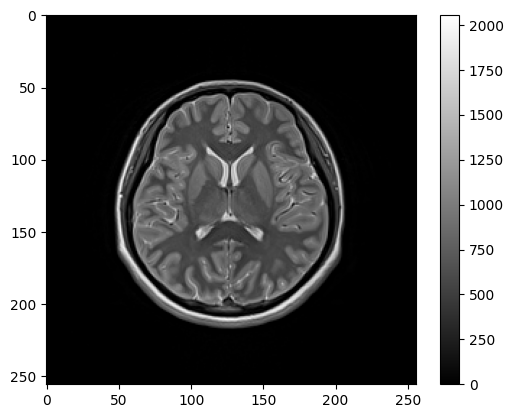

In [ ]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

## Exerceise 1: Automatic Basic Global Thresholding
- 강의노트의 내용을 기반으로 하여 자동으로 global thresholding을 수행하는 영상처리코드를 작성하고, 적용한 결과를 확인하자.

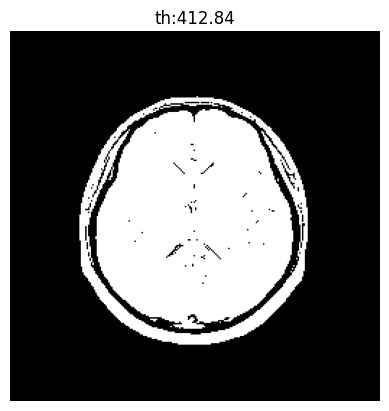

In [15]:
img = mri[::-1, ::-1, 18].transpose((1, 0))

T_init = 1
T = []
T.append(T_init)
dT = 1000
esp = 5

## write down your algorithm
while dT > esp:
    G1 = img[img > T[-1]]
    G2 = img[img <= T[-1]]

    m1 = np.mean(G1)
    m2 = np.mean(G2)

    T_new = 0.5 * (m1 + m2)
    dT = np.abs(T_new - T[-1])
    T.append(T_new)
##

bmsk = img > T[-1]
plt.imshow(bmsk, cmap='gray')
plt.axis('off')
plt.title(f'th:{T[-1]:.2f}')
plt.show()

## Exercise 2: K-means clustering
- 강의노트의 "standard" k-means clustering algorithm을 완성하여 s02.nii.gz 파일에 적용해보자.
- k=2,3,4 일 때의 결과를 s02.nii.gz에 대해 각각 비교해보자.

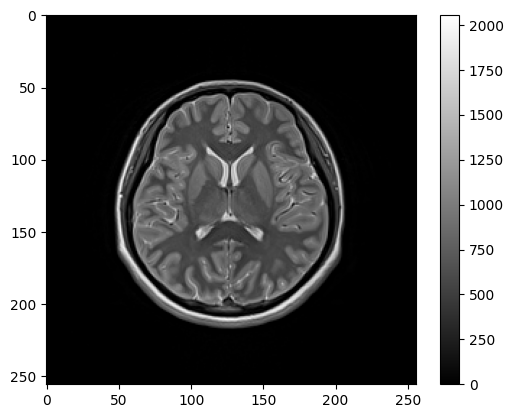

In [13]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

### k = 2 에서의 결과

[ 64. 128.]
[  5.91248043 768.93253625]
[ 13.3779618  806.97810069]
[ 14.87874927 810.79294742]


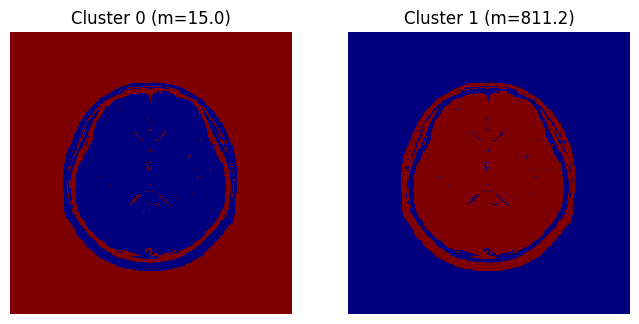

In [16]:
m_vals = np.array([64., 128.])
c = np.zeros((f.shape[0], f.shape[1], len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E = 10000
eps = 1
cmap = np.argmin(c, axis=-1)

while E > eps:
    print(m_vals)
    ##
    # 1. 각 픽셀과 각 클러스터 중심(m_vals[i]) 사이의 거리 계산
    for i in range(len(m_vals)):
        c[:, :, i] = np.abs(f - m_vals[i])

    # 2. 가장 가까운 클러스터로 각 픽셀 할당
    cmap = np.argmin(c, axis=-1)

    # 3. 할당된 픽셀들의 평균으로 새로운 중심값 계산
    for i in range(len(m_vals)):
        if np.any(cmap == i):  # 빈 클러스터로 인한 NaN 방지
            m_vals_new[i] = np.mean(f[cmap == i])
        else:
            m_vals_new[i] = m_vals[i]

    # 4. 중심값 변화량 계산 및 중심값 갱신
    E = np.sum(np.abs(m_vals_new - m_vals))
    m_vals = m_vals_new.copy()
    ##

plt.figure(figsize=(8, 4))
for i in range(len(m_vals)):
    plt.subplot(1, len(m_vals), i + 1)
    plt.imshow(cmap == i, cmap='jet', interpolation='nearest')
    plt.title(f'Cluster {i} (m={m_vals[i]:.1f})')
    plt.axis('off')
plt.show()

### k = 3 에서의 결과

[  64.  500. 1000.]
[   9.23535482  570.52432046 1006.69900059]
[   9.46603923  589.4350425  1031.20731048]
[   9.80914609  603.09512864 1049.00640429]
[  10.0145394   613.57100517 1064.17498138]
[  10.17157989  621.26118729 1076.07332985]
[  10.29753675  627.84005118 1087.00860656]
[  10.52586018  634.42087989 1097.94594595]
[  10.66149543  640.20486164 1108.70843301]
[  10.74363231  645.53805283 1119.62298671]
[  10.84722556  650.12659066 1129.30026025]
[  10.90286238  654.67665968 1139.86507128]
[  11.0008076   659.28618094 1150.9249867 ]
[  11.11352578  663.77924528 1162.20778499]
[  11.19872172  667.69767121 1172.77254296]
[  11.26299834  671.88515026 1184.99817924]
[  11.35628475  675.79313345 1196.78134912]
[  11.4789024   680.06710657 1210.27872861]
[  11.56606528  684.18477554 1224.57935393]
[  11.63900749  687.83516484 1238.13706706]
[  11.71967767  691.30365993 1251.68426474]
[  11.80821739  694.71303747 1265.69170494]
[  11.86755198  697.87517889 1279.73031161]
[  11.904788

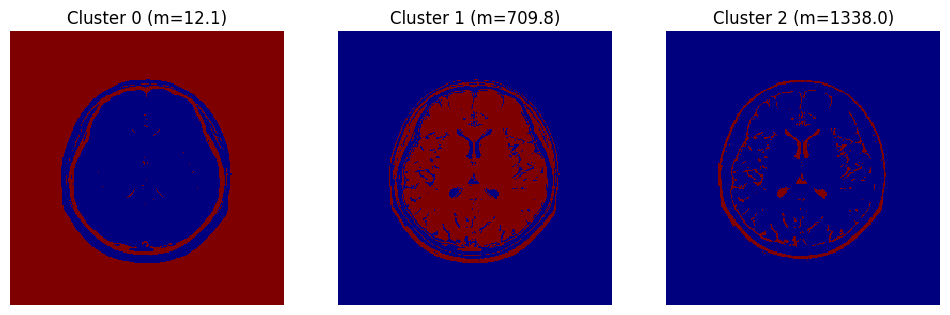

In [17]:
m_vals = np.array([64., 500., 1000.])
c = np.zeros((f.shape[0], f.shape[1], len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E = 10000
eps = 1
cmap = np.argmin(c, axis=-1)

while E > eps:
    print(m_vals)
    for i in range(len(m_vals)):
        c[:, :, i] = np.abs(f - m_vals[i])

    cmap = np.argmin(c, axis=-1)

    for i in range(len(m_vals)):
        if np.any(cmap == i):
            m_vals_new[i] = np.mean(f[cmap == i])
        else:
            m_vals_new[i] = m_vals[i]

    E = np.sum(np.abs(m_vals_new - m_vals))
    m_vals = m_vals_new.copy()

plt.figure(figsize=(12, 4))
for i in range(len(m_vals)):
    plt.subplot(1, len(m_vals), i + 1)
    plt.imshow(cmap == i, cmap='jet', interpolation='nearest')
    plt.title(f'Cluster {i} (m={m_vals[i]:.1f})')
    plt.axis('off')
plt.show()

### k = 4 에서의 결과

[  64.  400.  800. 1200.]
[   7.98223507  502.01416208  799.21549044 1304.25783651]
[   8.56485273  528.67451235  840.42333096 1377.64870105]
[   8.93702328  543.3555158   864.94074932 1436.3919295 ]
[   9.12865176  552.10360105  879.65710898 1472.43419689]
[   9.19950371  556.73491976  888.25150027 1495.15239155]
[   9.23535482  559.39928018  893.00593994 1506.96997691]
[   9.30759944  561.31231069  895.59780804 1512.28009395]
[   9.33180421  562.34377354  897.19520053 1515.7891924 ]
[   9.33180421  562.77316157  898.05495606 1518.02093301]
[   9.35609253  563.39308277  898.78677373 1519.1392557 ]
[   9.35609253  563.98324797  899.40653683 1519.1392557 ]
[   9.35609253  563.98324797  899.5797069  1520.07284768]


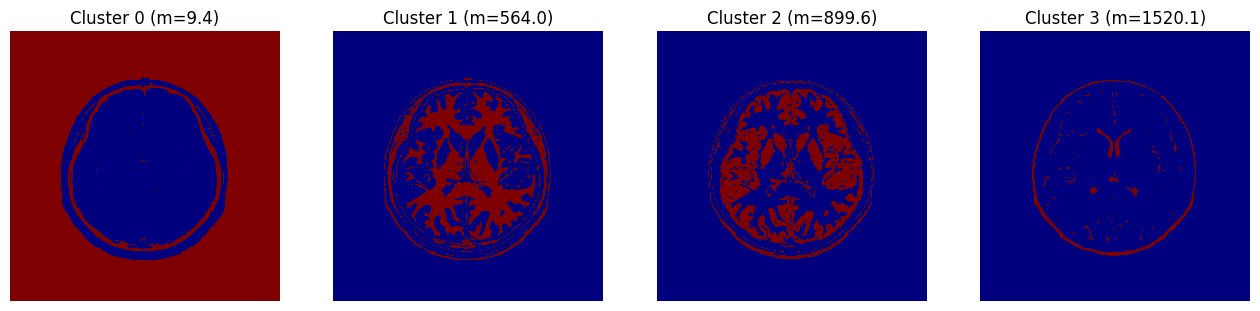

In [18]:
m_vals = np.array([64., 400., 800., 1200.])
c = np.zeros((f.shape[0], f.shape[1], len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E = 10000
eps = 1
cmap = np.argmin(c, axis=-1)

while E > eps:
    print(m_vals)
    for i in range(len(m_vals)):
        c[:, :, i] = np.abs(f - m_vals[i])

    cmap = np.argmin(c, axis=-1)

    for i in range(len(m_vals)):
        if np.any(cmap == i):
            m_vals_new[i] = np.mean(f[cmap == i])
        else:
            m_vals_new[i] = m_vals[i]

    E = np.sum(np.abs(m_vals_new - m_vals))
    m_vals = m_vals_new.copy()

plt.figure(figsize=(16, 4))
for i in range(len(m_vals)):
    plt.subplot(1, len(m_vals), i + 1)
    plt.imshow(cmap == i, cmap='jet', interpolation='nearest')
    plt.title(f'Cluster {i} (m={m_vals[i]:.1f})')
    plt.axis('off')
plt.show()